# S3 event STAR — IS diagnosis (sealed OOS off-limits)

Failure forensics on the **frozen event** STAR using **research IS only**.

The event sleeve is **always Forex** (G10 + calendar). It does not follow core `UNIVERSE_STAR`.

**Do not** load sealed OOS here. Disposition: kill / paper / new H — never re-tune on the sealed slice.


## 0. Imports & Config


In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(ROOT, "01_data", "ingestion")):
    parent = os.path.dirname(ROOT)
    if parent == ROOT:
        break
    ROOT = parent
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from backtest.s3_trend.report import fold_val_metrics, load_star_stack
from backtest.s3_trend.research import (
    RESEARCH_IS_END_S3,
    config_from_stack,
    n_trials_ledger_total,
    star_stack_path,
)
from backtest.s3_trend.runner import run_s3_backtest
from backtest.s3_trend.tearsheet import (
    baseline_configs_from_star,
    check_fill_timing,
    cost_stress_sharpes,
    daily_regime_performance,
    early_late_is_decay,
    equity_from_returns,
    ew_long_g10_returns,
    oos_headline_metrics,
    pair_pnl_attribution,
    pair_scorecard,
    plot_drawdown,
    plot_equity_net_gross,
    spy_daily_returns,
    utilization_stats,
)
from backtest.s3_trend.walkforward import embargo_bars_for_config, make_s3_folds
from data.processing.s3_fx_price_panel import price_panel_path, s3_data_dir
from strategies.s3_trend.metrics import (
    load_s1_period_returns,
    load_s2_period_returns,
    metrics_from_returns,
)

SLEEVE = "event"
IS_END = pd.Timestamp(RESEARCH_IS_END_S3)
DATA_DIR = s3_data_dir(ROOT)
ARTIFACTS = os.path.join(ROOT, "04_backtest", "s3_trend", "artifacts")
os.makedirs(ARTIFACTS, exist_ok=True)
STACK_PATH = star_stack_path(SLEEVE)
stack = load_star_stack(STACK_PATH)
N_STACK = n_trials_ledger_total(sleeve=SLEEVE)
print("BANNER: IS-only diagnosis — sealed OOS is off-limits")
print(STACK_PATH)
print(f"IS_END={IS_END.date()}  n_trials_stack={N_STACK}")
display(pd.Series(stack, name="value").to_frame())


BANNER: IS-only diagnosis — sealed OOS is off-limits
C:\Users\User\Desktop\ML Algorithmic Trading\Portfolio 26\trading_portfolio\04_backtest\s3_trend\artifacts\s3_event_star_stack.json
IS_END=2016-12-31  n_trials_stack=8


,value
EVENT_Z_GATE_STAR,None
K_STAR,None
EVENT_IMPACT_MIN_STAR,None
EVENT_HOLD_BARS_STAR,None
EVENT_BAR_STAR,None
SURPRISE_SIZING_STAR,None
COST_PROFILE_STAR,None


## 1. Contract


In [2]:
print("Timing: signal at close t → fill open t+1 (S3 contract)")
print("Costs: A_FX_OANDA_S3 spread + slippage + swap (unless COST_PROFILE_STAR set)")
print("Day boundary: 17:00 America/New_York (pre-registered)")
print("Disposition from this notebook: kill / paper / new H — never re-tune on sealed OOS")


Timing: signal at close t → fill open t+1 (S3 contract)
Costs: A_FX_OANDA_S3 spread + slippage + swap (unless COST_PROFILE_STAR set)
Day boundary: 17:00 America/New_York (pre-registered)
Disposition from this notebook: kill / paper / new H — never re-tune on sealed OOS


## 2. Run frozen STAR on IS only


In [3]:
path = price_panel_path("1d", data_dir=DATA_DIR)
if not os.path.isfile(path):
    raise FileNotFoundError(path)
panel = pd.read_parquet(path)
panel["date"] = pd.to_datetime(panel["date"])
panel_is = panel.loc[panel["date"] <= IS_END].copy()
assert (panel_is["date"] > IS_END).sum() == 0, "OOS rows leaked into IS panel"

rates_path = os.path.join(DATA_DIR, "g10_policy_rates.parquet")
rates = pd.read_parquet(rates_path) if os.path.isfile(rates_path) else pd.DataFrame()
reer_path = os.path.join(DATA_DIR, "bis_reer_monthly.parquet")
reer = pd.read_parquet(reer_path) if os.path.isfile(reer_path) else pd.DataFrame()
if not rates.empty and "date" in rates.columns:
    rates = rates.loc[pd.to_datetime(rates["date"]) <= IS_END].copy()
if not reer.empty and "date" in reer.columns:
    reer = reer.loc[pd.to_datetime(reer["date"]) <= IS_END].copy()

cfg = config_from_stack(stack)
s1_weekly = load_s1_period_returns()
s2_daily = load_s2_period_returns()
if s1_weekly.empty:
    warnings.warn("S1 period returns missing — corr_to_s1 will be NaN")
if s2_daily.empty:
    warnings.warn("S2 period returns missing — corr_to_s2 will be NaN")

spy = spy_daily_returns(panel_is["date"].min(), panel_is["date"].max())
res = run_s3_backtest(
    panel_is,
    cfg,
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
is_net = res.returns
is_gross = res.returns_gross
print("IS bars", len(panel_is), "return days", len(is_net))
print(cfg)


IS bars 21580 return days 3164
S3SimConfig(pairs=('EURUSD', 'USDJPY', 'GBPUSD', 'USDCHF', 'USDCAD', 'AUDUSD', 'NZDUSD'), bar='1d', day_boundary_tz='America/New_York', day_boundary_hour=17, signal_family='tsmom', tsmom_lookbacks=(21, 63, 252), tsmom_blend='single_12m', donchian_n=55, donchian_hl_source='daily_ny_close', pair_vt=False, book_vt=False, vt_target_ann_vol=0.1, conviction_scaling='sign', weak_signal_flat_z=0.0, rebalance_band=0.0, carry_mode='off', carry_refresh='weekly', value_mode='off', value_refresh='monthly', carry_agree_scale=1.25, carry_disagree_scale=0.75, value_agree_scale=1.25, value_disagree_scale=0.75, spike_mode='off', spike_threshold_sigmas=2.0, corr_conflict_mode='off', corr_gate_threshold=0.85, currency_cap_gross_pct=0.5, cost_profile='A_FX_OANDA_S3', include_swap=True, financing_spread_bps_annual=50.0, cost_multiplier=1.0, event_z_gate=1.0, event_impact_min=2, event_hold_bars=1, event_bar='1d', surprise_sizing=False)


## 3. Headline IS metrics (gross vs net)


,IS
ann_sharpe_net,-0.107171
ann_sharpe_gross,-0.024916
sortino,-0.130680
calmar,-0.030802
max_drawdown,-0.298671
cagr,-0.009200
total_return,-0.109560
psr,0.352038
dsr_local,0.352038
dsr_stack,0.032932


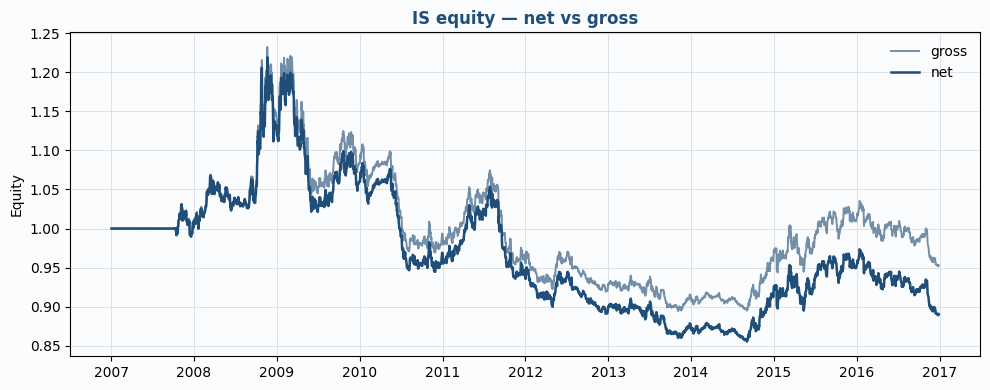

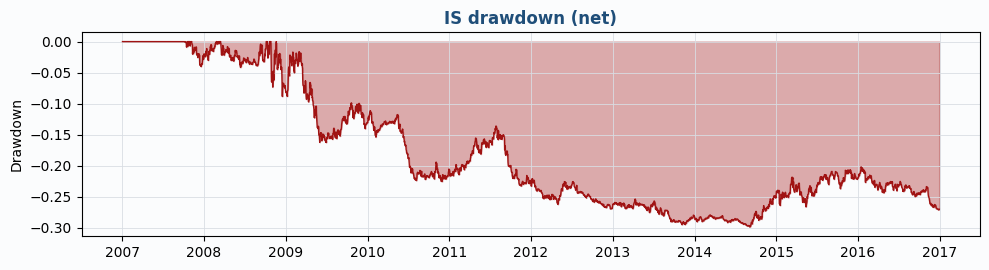

In [4]:
headline = oos_headline_metrics(
    is_net,
    is_gross,
    trades=res.pair_trades,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    spy_daily=spy if not spy.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(headline.to_frame("IS"))
fig = plot_equity_net_gross(is_net, is_gross, title="IS equity — net vs gross")
plt.show()
fig = plot_drawdown(is_net, title="IS drawdown (net)")
plt.show()


## 4. Fold-val consistency + early/late IS decay


In [5]:
is_dates = pd.DatetimeIndex(panel_is["date"].drop_duplicates().sort_values())
folds = make_s3_folds(
    is_dates,
    n_folds=3,
    embargo_bars=embargo_bars_for_config(bar=str(cfg.bar)),
)
fold_df = fold_val_metrics(
    panel_is,
    folds,
    {"frozen_star": cfg},
    hyp_id=None,  # reporting only — stack DSR already set on full-IS run
    sleeve=SLEEVE,
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
)
display(fold_df)
decay = early_late_is_decay(is_net)
display(decay.to_frame("value"))


,arm,fold_id,ann_sharpe,ann_sharpe_gross,max_drawdown,calmar,corr_to_s1,corr_to_s2,psr,dsr_local,dsr_stack,skew,excess_kurtosis,cost_bps_per_year,n_days,n_entries,n_trials_local,n_trials_stack
0,frozen_star,1,-0.440331,-0.434134,-0.170733,-0.170788,NaN,NaN,0.217610,NaN,NaN,-0.134096,2.074398,72.147719,790,114,None,None
1,frozen_star,2,-0.975219,-0.846617,-0.183724,-0.262803,NaN,NaN,0.040359,NaN,NaN,-0.539569,6.557795,150.660728,789,245,None,None
2,frozen_star,3,0.147214,0.288514,-0.086860,0.083419,0.155376,NaN,0.602448,NaN,NaN,-0.647813,5.100483,82.062921,790,146,None,None


,value
early_sharpe,0.070999
late_sharpe,-0.345951
decay_ratio,-4.872634
n_early,1583.0
n_late,1581.0
midpoint,2011-06-19


## 5. Pair scorecard + attribution (IS)


,pair,ann_sharpe_net,ann_sharpe_gross,max_drawdown,n_trades,cost_bps_year,n_days
1,USDJPY,0.295476,0.368700,-0.182367,51,7.198357,3099
2,GBPUSD,0.088518,0.165152,-0.348994,53,5.712260,3091
4,USDCAD,-0.077828,0.001867,-0.329595,92,16.973546,3065
6,NZDUSD,-0.121580,-0.091314,-0.517574,76,15.368862,3056
5,AUDUSD,-0.142117,-0.119865,-0.535258,86,12.083714,3071
0,EURUSD,-0.150013,-0.091342,-0.327607,83,8.692137,3095
3,USDCHF,-0.294349,-0.247545,-0.531375,102,17.083605,3089


,is_total_return
USDCHF,-0.384508
AUDUSD,-0.276594
NZDUSD,-0.248487
EURUSD,-0.202183
USDCAD,-0.130588
GBPUSD,0.049553
USDJPY,0.346115


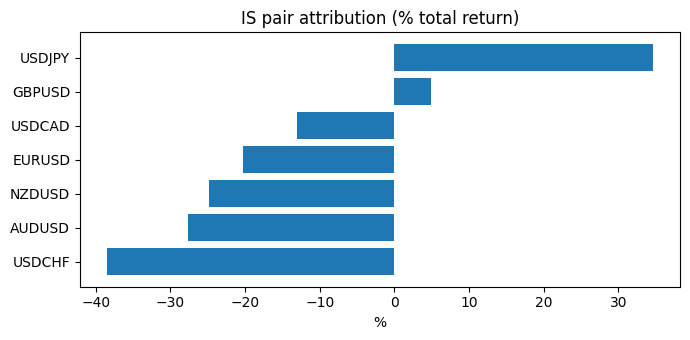

In [6]:
score = pair_scorecard(res.book, date_max=IS_END)
attr = pair_pnl_attribution(res.book, date_max=IS_END)
display(score.sort_values("ann_sharpe_net", ascending=False))
display(attr.to_frame("is_total_return"))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(list(attr.index), 100.0 * attr.values)
ax.set_title("IS pair attribution (% total return)")
ax.set_xlabel("%")
plt.tight_layout()
plt.show()


## 6. Utilization + friction


In [7]:
util = utilization_stats(is_net, res.pair_trades, weights=res.book.weights)
display(util.to_frame("value"))


,value
pct_days_nonzero,0.916561
n_trades,543.000000
mean_gross_exposure,6.258217


## 7. Cost stress (IS)


In [8]:
stress = cost_stress_sharpes(
    panel_is,
    cfg,
    multipliers=(1.0, 1.5, 2.0),
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    s1_weekly=s1_weekly if not s1_weekly.empty else None,
    s2_daily=s2_daily if not s2_daily.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
display(stress)


,cost_multiplier,ann_sharpe_net,ann_sharpe_gross,max_drawdown,cost_bps_per_year,n_entries
0,1.0,-0.107171,-0.024916,-0.298671,80.827425,543
1,1.5,-0.147301,-0.024916,-0.314072,121.241137,543
2,2.0,-0.187424,-0.024916,-0.329135,161.654849,543


## 8. Regimes (IS)


In [9]:
regimes = daily_regime_performance(is_net, spy, is_dates)
display(regimes["vol_cutpoints"].to_frame("value"))
display(regimes["market"])
display(regimes["vol"])


,value
q33,0.007842
q66,0.011401


,n,mean_return,total_return,sharpe,win_rate
regime,,,,,
Down,1018,-0.000329,-0.292067,-1.140536,0.438114
Up,1231,0.000154,0.196274,0.591905,0.482535


,n,mean_return,total_return,sharpe,win_rate
regime,,,,,
High,741,-0.000293,-0.204580,-0.814129,0.456140
Low,740,-0.000021,-0.019126,-0.112467,0.462162
Mid,741,0.000118,0.085458,0.477220,0.485830
Unknown,27,0.000000,0.000000,NaN,0.000000


## 9. Baselines (raw TSMOM + EW long G10)


In [10]:
baselines = baseline_configs_from_star(cfg)
raw_res = run_s3_backtest(
    panel_is,
    baselines["raw_tsmom"],
    rates_df=rates if not rates.empty else None,
    reer_df=reer if not reer.empty else None,
    n_trials_local=1,
    n_trials_stack=N_STACK,
)
ew = ew_long_g10_returns(panel_is)
ew = ew.reindex(is_net.index).dropna()
rows = {
    "frozen_star": metrics_from_returns(is_net),
    "raw_tsmom": metrics_from_returns(raw_res.returns),
    "ew_long_g10": metrics_from_returns(ew),
}
base_df = pd.DataFrame(rows).T
display(base_df)


,ann_sharpe,max_drawdown,calmar,n_days
frozen_star,-0.107171,-0.298671,-0.030802,3164.0
raw_tsmom,-0.107171,-0.298671,-0.030802,3164.0
ew_long_g10,-0.161798,-0.216850,-0.040619,3164.0


## 10. Fill-timing assert


In [11]:
timing = check_fill_timing(res.pair_trades, panel_is)
display(timing.head())
print("all_ok rate", float(timing["all_ok"].mean()) if not timing.empty else float("nan"))
if not timing.empty and not bool(timing["all_ok"].all()):
    warnings.warn("Some trades failed fill-timing checks — inspect before trusting PnL")


,pair,entry_date,signal_date,ok_signal_before_fill,ok_fill_has_open,ok_not_same_bar_close_fill,all_ok
0,EURUSD,2007-10-12,2007-10-11,True,True,True,True
1,EURUSD,2008-08-26,2008-08-25,True,True,True,True
2,EURUSD,2008-08-27,2008-08-26,True,True,True,True
3,EURUSD,2008-08-31,2008-08-30,True,True,True,True
4,EURUSD,2008-09-22,2008-09-21,True,True,True,True


all_ok rate 1.0


## 11. Cause-class checklist + post-mortem stub

Paste into `02_research/s3_trend/s3_core_hypothesis_log.md` after filling blanks.


In [12]:
stub = f"""
### Post-mortem — event STAR IS diagnosis

- Date: {pd.Timestamp.utcnow().strftime('%Y-%m-%d')}
- IS net Sharpe: {headline.get('ann_sharpe_net', float('nan')):.3f}
- IS gross Sharpe: {headline.get('ann_sharpe_gross', float('nan')):.3f}
- Cost bps/year: {headline.get('cost_bps_year', float('nan')):.1f}
- Early/late decay: {decay.get('decay_ratio', float('nan')):.3f}
- Cost stress 2.0× Sharpe: {float(stress.loc[stress['cost_multiplier']==2.0, 'ann_sharpe_net'].iloc[0]) if (stress['cost_multiplier']==2.0).any() else float('nan'):.3f}

**Cause class (pick one):** cost / overfit (fold vs full-IS) / regime / bug / no edge

**Evidence:**
- 

**Disposition:** kill / paper / new H-id (do not re-test sealed OOS after recipe changes)
"""
print(stub)



### Post-mortem — event STAR IS diagnosis

- Date: 2026-10-29
- IS net Sharpe: -0.107
- IS gross Sharpe: -0.025
- Cost bps/year: 80.8
- Early/late decay: -4.873
- Cost stress 2.0× Sharpe: -0.187

**Cause class (pick one):** cost / overfit (fold vs full-IS) / regime / bug / no edge

**Evidence:**
- 

**Disposition:** kill / paper / new H-id (do not re-test sealed OOS after recipe changes)

